# Exercise 1

## Load data from Harry Potter

In [1]:
import nltk

file = open("chamber_of_secrets.txt", "r")
raw = file.read().replace("\n", " ").strip()
file.close()

chapters = ["CHAPTER" + chapter for chapter in raw.split("CHAPTER")]

# Remove title
chapters.pop(0)

print(chapters[0][0:500])


CHAPTER ONE  THE BOY WHO LIVED  Mr. and Mrs. Dursley, of number four, Privet Drive, were proud to say that they were perfectly normal, thank you very much. They were the last people you'd expect to be involved in anything strange or mysterious, because they just didn't hold with such nonsense.  Mr. Dursley was the director of a firm called Grunnings, which made drills. He was a big, beefy man with hardly any neck, although he did have a very large mustache. Mrs. Dursley was thin and blonde and h


OUPUT
```
CHAPTER ONE  THE BOY WHO LIVED  Mr. and Mrs. Dursley, of number four, Privet Drive, were proud to say that they were perfectly normal, thank you very much. They were the last people you'd expect to be involved in anything strange or mysterious, because they just didn't hold with such nonsense.  Mr. Dursley was the director of a firm called Grunnings, which made drills. He was a big, beefy man with hardly any neck, although he did have a very large mustache. Mrs. Dursley was thin and blonde and h
```

## 1.1)

In [2]:
def chunkSent(sent, parser):
    return parser.parse(sent)

def extractPosTaggedSents(sents):
    sents = nltk.sent_tokenize(sents)
    sents = [nltk.word_tokenize(sent) for sent in sents]
    return [nltk.pos_tag(sent) for sent in sents]

def fetchEntities(text):
    sents = extractPosTaggedSents(text)
    grammar = """
        ENTITIY: {<DT><JJ>?<NN.*>+}
                {<NNP>+}
                {<JJ>+<NN.*>+}
            """
    return [chunkSent(sent, nltk.RegexpParser(grammar)) for sent in sents]


trees = []

for chapter in chapters:
    trees += fetchEntities(chapter)

(S
  CHAPTER/NN
  ONE/CD
  (ENTITIY THE/NNP BOY/NNP WHO/NNP LIVED/NNP Mr./NNP)
  and/CC
  (ENTITIY Mrs./NNP Dursley/NNP)
  ,/,
  of/IN
  number/NN
  four/CD
  ,/,
  (ENTITIY Privet/NNP Drive/NNP)
  ,/,
  were/VBD
  proud/JJ
  to/TO
  say/VB
  that/IN
  they/PRP
  were/VBD
  perfectly/RB
  normal/JJ
  ,/,
  thank/NN
  you/PRP
  very/RB
  much/RB
  ./.)
(S
  They/PRP
  were/VBD
  (ENTITIY the/DT last/JJ people/NNS)
  you/PRP
  'd/MD
  expect/VB
  to/TO
  be/VB
  involved/VBN
  in/IN
  anything/NN
  strange/JJ
  or/CC
  mysterious/JJ
  ,/,
  because/IN
  they/PRP
  just/RB
  did/VBD
  n't/RB
  hold/VB
  with/IN
  (ENTITIY such/JJ nonsense/NN)
  ./.)
(S
  (ENTITIY Mr./NNP Dursley/NNP)
  was/VBD
  (ENTITIY the/DT director/NN)
  of/IN
  (ENTITIY a/DT firm/NN)
  called/VBN
  (ENTITIY Grunnings/NNP)
  ,/,
  which/WDT
  made/VBD
  drills/NNS
  ./.)
(S
  He/PRP
  was/VBD
  a/DT
  big/JJ
  ,/,
  (ENTITIY beefy/JJ man/NN)
  with/IN
  hardly/RB
  (ENTITIY any/DT neck/NN)
  ,/,
  although/IN
  he/PR

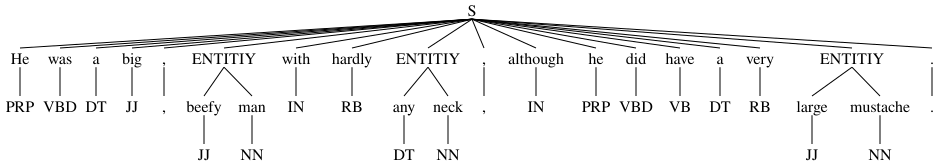

In [3]:
for i in range(5):
    print(trees[i])

trees[3]

Can't get tkinter to work on my PC, so I strugged a bit with drawing the trees. Hope this is enough.
![tree](11.png)
OUTPUT
```
(S
  CHAPTER/NN
  ONE/CD
  (ENTITIY THE/NNP BOY/NNP WHO/NNP LIVED/NNP Mr./NNP)
  and/CC
  (ENTITIY Mrs./NNP Dursley/NNP)
  ,/,
  of/IN
  number/NN
  four/CD
  ,/,
  (ENTITIY Privet/NNP Drive/NNP)
  ,/,
  were/VBD
  proud/JJ
  to/TO
  say/VB
  that/IN
  they/PRP
  were/VBD
  perfectly/RB
  normal/JJ
  ,/,
  thank/NN
  you/PRP
...
  spying/VBG
  on/IN
  (ENTITIY the/DT neighbors/NNS)
  ./.)
```

## 1.2)

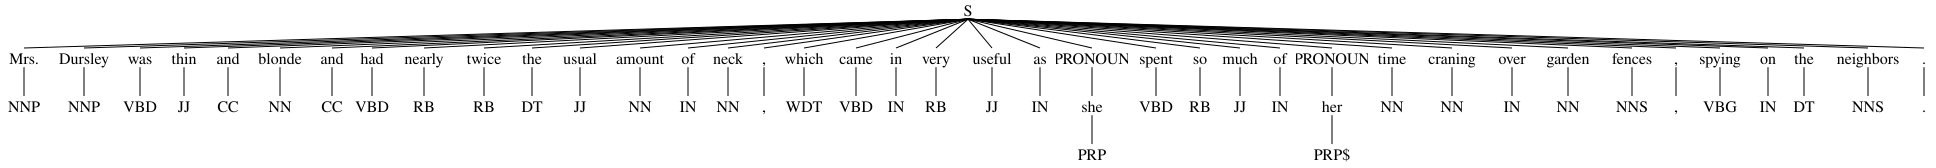

In [4]:
def chunkPronouns(text):
    grammar = """
        PRONOUN: {<PR.*>}
    """
    sents = extractPosTaggedSents(text)
    return [chunkSent(sent, nltk.RegexpParser(grammar)) for sent in sents]
    
pronounTrees = []

for chapter in chapters:
    pronounTrees += chunkPronouns(chapter)

pronounTrees[4]

OUTPUT 
```
(S
  (PRONOUN They/PRP)
  were/VBD
  the/DT
  last/JJ
  people/NNS
  (PRONOUN you/PRP)
  'd/MD
  expect/VB
  to/TO
  be/VB
  involved/VBN
  in/IN
  anything/NN
  strange/JJ
  or/CC
  mysterious/JJ
  ,/,
  because/IN
  (PRONOUN they/PRP)
  just/RB
  did/VBD
  n't/RB
  hold/VB
  with/IN
  such/JJ
  nonsense/NN
  ./.)
```

To attribute a pronoun to an entity I would probably use some sort off n-gram to check how many times a pronoun is used close to an entitiy. This wouldn't work all of the times since there can be a lot of entities being talked about close to each other, but it could give a stastical indication. 

## 1.3)

In [5]:
def NERWithNLTK(sent):
    return nltk.ne_chunk(sent)

chapterTwoSents = extractPosTaggedSents(chapters[1])

entities = [NERWithNLTK(sent) for sent in chapterTwoSents]
recognisedEntities = []

for entity in entities:
    for subtree in entity.subtrees():
        if not subtree.label() == "S": 
            # leaves = " ".join([leaf[0] for leaf in subtree.leaves()])
            recognisedEntities.append(subtree.label())


def getTopN(list, n):
    return nltk.FreqDist(list).most_common(n)

print(getTopN(recognisedEntities, 10))


[('PERSON', 187), ('ORGANIZATION', 31), ('GPE', 21), ('GSP', 1)]


OUTPUT
```
[('PERSON', 187), ('ORGANIZATION', 31), ('GPE', 21), ('GSP', 1)]
```

## 1.4)


In [6]:
import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp(chapters[1])
recognisedEntities = []
for ent in doc.ents:
    recognisedEntities.append(ent.label_)

print(getTopN(recognisedEntities, 10))

[('PERSON', 170), ('DATE', 19), ('GPE', 17), ('CARDINAL', 14), ('ORDINAL', 9), ('LOC', 9), ('ORG', 7), ('TIME', 3), ('NORP', 2), ('LAW', 1)]


OUTPUT
```
[('PERSON', 170), ('DATE', 19), ('GPE', 17), ('CARDINAL', 14), ('ORDINAL', 9), ('LOC', 9), ('ORG', 7), ('TIME', 3), ('NORP', 2), ('LAW', 1)]
```
Spacy has a lot more entity types than the built-in nltk one.

## 1.5)

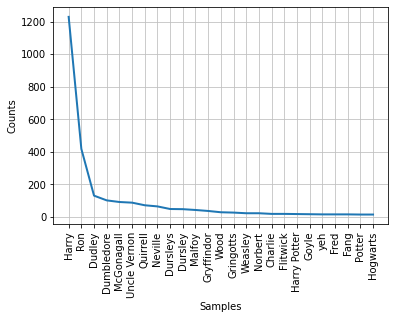

<AxesSubplot:xlabel='Samples', ylabel='Counts'>

In [7]:
# Use raw from when I read from file
doc = nlp(raw)

people = []
for ent in doc.ents:
    if ent.label_ == "PERSON":
        people.append(ent.text)

# Too make the graph readable:-)
freq = nltk.FreqDist(dict(getTopN(people, 25)))
freq.plot()


![16.png](16.png)

## 1.6)

In [8]:
from spacy import displacy
displacy.render(list(doc.sents)[4], style="dep")

PS: Picture to long to screenshot:)

When looking at this I do not think I would have come very far with what I figured out in task 2. But here it is very easy to see what pronouns are connected to which entities, since you can follow the lines. So with this data I could much easier connect the two.

# Exercise 2


In [67]:
from qwikidata.linked_data_interface import get_entity_dict_from_api
from qwikidata.entity import WikidataItem
import requests


# Borrowed from your github:)
def find_entity(ent):
    ent = ent.replace(" ", "_")
    wikidata_search = f"https://www.wikidata.org/w/api.php?action=wbsearchentities&search={ent}&language=en&format=json"

    res = requests.get(wikidata_search)
    if res.status_code == 200:
        return res.json()
    return {}

def get_ent_id(ent):
    for entry in ent["search"]:
        if "character" in entry["description"]:
            return entry["id"]

def getDataAboutEntity(entity):
    entityData = find_entity(entity)
    entityID = get_ent_id(entityData)
    entityDict = get_entity_dict_from_api(entityID)
    return WikidataItem(entityDict)


def getGenderOfEntity(entity):
    data = getDataAboutEntity(entity)
    genderID = data.get_claim_group("P21")._claim_list[0].get("mainsnak").get("datavalue").get("value").get("id")
    if genderID == "Q6581097":
        return "male"
    return "female"

print(getGenderOfEntity("Uncle Vernon"))
print(getGenderOfEntity("Harry Potter"))


male
male
